# Introduction to Hypothesis Testing

Hypothesis testing is a **formal statistical framework** for evaluating whether a sample provides enough evidence to infer a property of a population.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Formulation of Hypotheses

- **Null Hypothesis ($H_0$)** — the default assumption, e.g. $H_0: \mu = \mu_0$ (no difference).
- **Alternative Hypothesis ($H_a$ or $H_1$)** — the claim we investigate:
  - **Two-sided**: $H_a: \mu \neq \mu_0$
  - **Right-tailed**: $H_a: \mu > \mu_0$
  - **Left-tailed**: $H_a: \mu < \mu_0$

## 2. Significance Level and Errors

$$
\alpha = P(\text{Reject } H_0 \mid H_0 \text{ is true})
$$

| | $H_0$ true | $H_0$ false |
|---|---|---|
| **Reject $H_0$** | Type I error (prob. $\alpha$) | Correct (**power** $= 1-\beta$) |
| **Fail to reject** | Correct | Type II error (prob. $\beta$) |

Typical choices: $\alpha = 0.05$ or $0.01$. Smaller $\alpha$ → fewer false positives, but more false negatives.

## 3. Decision Rule Using the p-value

The **p-value** is the probability of observing a test statistic at least as extreme as the one computed from the sample, **assuming $H_0$ is true**.

$$
\text{If } p < \alpha \;\Rightarrow\; \text{reject } H_0, \quad \text{otherwise fail to reject } H_0.
$$

A p-value is **not** the probability that $H_0$ is true, and "fail to reject" is **not** proof that $H_0$ is true.

## 4. Choice of Test Statistic

- **Z-test**: population variance known (or $n$ large). $\;Z = \dfrac{\bar{X} - \mu_0}{\sigma / \sqrt{n}}$
- **t-test**: variance unknown, estimated from the sample. $\;t = \dfrac{\bar{X} - \mu_0}{s / \sqrt{n}},\; df = n-1$
- **$\chi^2$-test**: categorical counts. $\;\chi^2 = \sum \dfrac{(O_i - E_i)^2}{E_i}$
- **F-test / ANOVA**: comparing several means. $\;F = \dfrac{\text{variance between groups}}{\text{variance within groups}}$

For a two-sided t-test we reject $H_0$ if $|t| > t_{\alpha/2,\,df}$.

## 5. Z-Test Example

Sample mean      : 102.815 


Z-test statistic : 1.991 


Critical value   : +/- 1.96 


p-value          : 0.0465 -> reject H0 


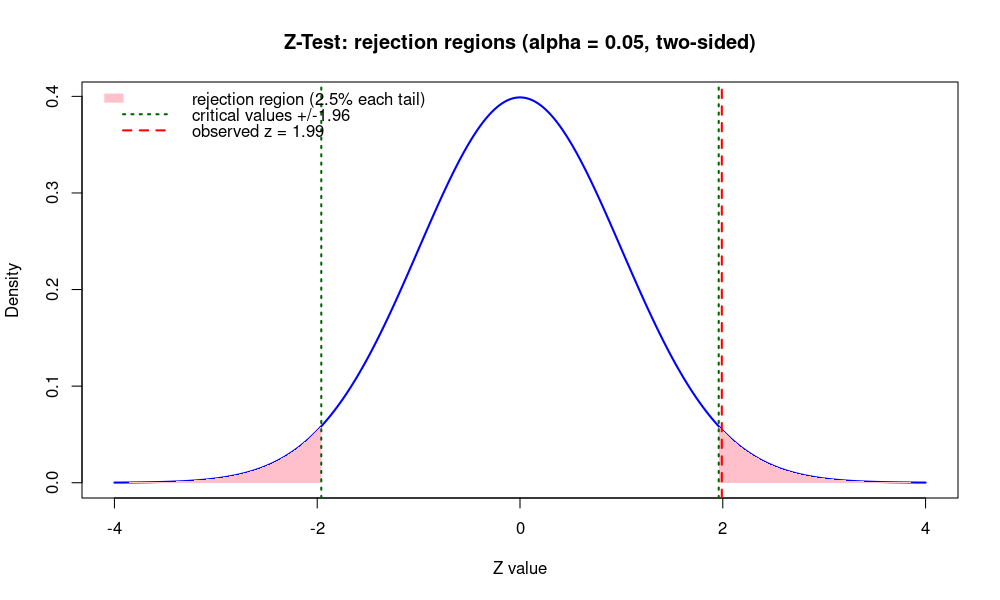

In [2]:
set.seed(100)
sample_data <- rnorm(50, mean = 102, sd = 10)
mu_0  <- 100   # hypothesized mean
sigma <- 10    # known population SD
n <- length(sample_data)

z_stat  <- (mean(sample_data) - mu_0) / (sigma / sqrt(n))
p_value <- 2 * (1 - pnorm(abs(z_stat)))
alpha   <- 0.05
z_crit  <- qnorm(1 - alpha / 2)

cat("Sample mean      :", round(mean(sample_data), 3), "\n")
cat("Z-test statistic :", round(z_stat, 3), "\n")
cat("Critical value   : +/-", round(z_crit, 3), "\n")
cat("p-value          :", round(p_value, 4), "->", ifelse(p_value < alpha, "reject H0", "fail to reject H0"), "\n")

x <- seq(-4, 4, length = 500); y <- dnorm(x)
plot(x, y, type = "l", lwd = 2, col = "blue",
     main = "Z-Test: rejection regions (alpha = 0.05, two-sided)", xlab = "Z value", ylab = "Density")
polygon(c(x[x <= -z_crit], -z_crit), c(y[x <= -z_crit], 0), col = "pink", border = NA)
polygon(c(x[x >= z_crit], z_crit), c(y[x >= z_crit], 0), col = "pink", border = NA)
abline(v = c(-z_crit, z_crit), col = "darkgreen", lwd = 2, lty = 3)
abline(v = z_stat, col = "red", lwd = 2, lty = 2)
legend("topleft", bty = "n",
       legend = c("rejection region (2.5% each tail)", sprintf("critical values +/-%.2f", z_crit),
                  sprintf("observed z = %.2f", z_stat)),
       fill = c("pink", NA, NA), border = c("pink", NA, NA),
       col = c(NA, "darkgreen", "red"), lty = c(NA, 3, 2), lwd = c(NA, 2, 2))

## 6. One-sample t-test


	One Sample t-test

data:  weights
t = -1.918, df = 29, p-value = 0.065
alternative hypothesis: true mean is not equal to 70
95 percent confidence interval:
 67.75874 70.07193
sample estimates:
mean of x 
 68.91534 



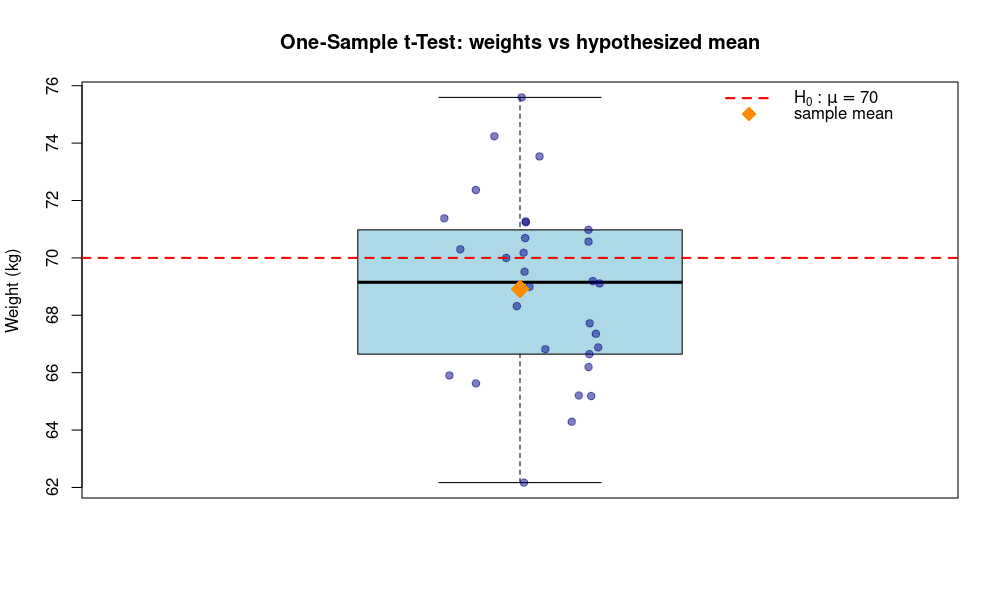

In [3]:
set.seed(21)
weights <- rnorm(30, mean = 69, sd = 3)
mu_0 <- 70

t_result <- t.test(weights, mu = mu_0)
print(t_result)

boxplot(weights, main = "One-Sample t-Test: weights vs hypothesized mean", ylab = "Weight (kg)",
        col = "lightblue", horizontal = FALSE)
stripchart(weights, vertical = TRUE, method = "jitter", pch = 19, col = adjustcolor("navy", 0.5), add = TRUE)
abline(h = mu_0, col = "red", lwd = 2, lty = 2)
points(1, mean(weights), pch = 18, cex = 2.5, col = "darkorange")
legend("topright", c(expression(H[0] ~ ":" ~ mu == 70), "sample mean"), col = c("red", "darkorange"),
       lty = c(2, NA), lwd = c(2, NA), pch = c(NA, 18), pt.cex = 2, bty = "n")

## 7. Two-Sample t-Test


	Two Sample t-test

data:  group1 and group2
t = -3.5384, df = 48, p-value = 0.000905
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 -8.258884 -2.273881
sample estimates:
mean of x mean of y 
 80.47880  85.74518 



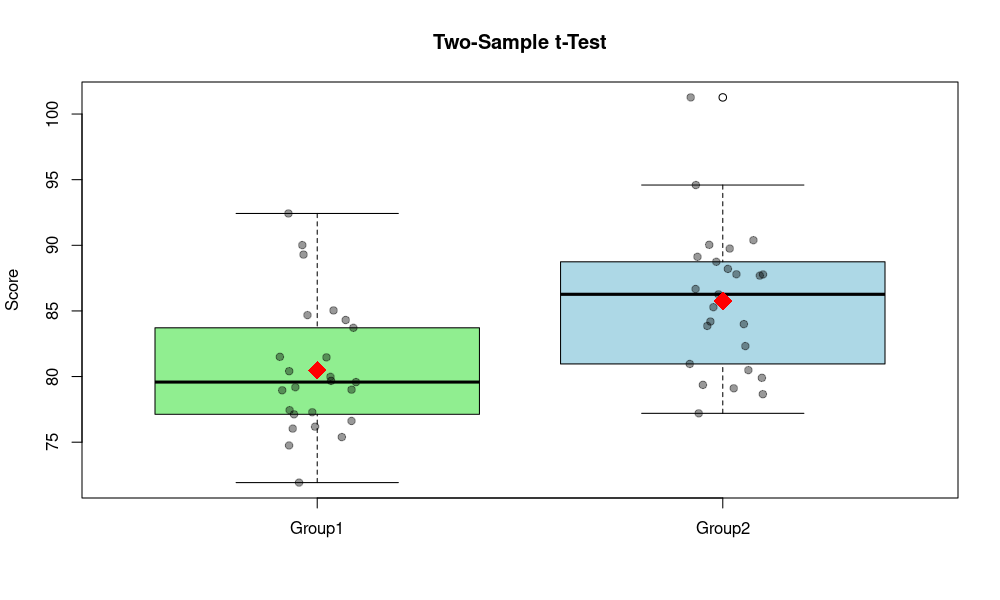

In [4]:
set.seed(22)
group1 <- rnorm(25, mean = 80, sd = 5)
group2 <- rnorm(25, mean = 85, sd = 5)

t2_result <- t.test(group1, group2, var.equal = TRUE)  # Student's t-test (equal variances)
print(t2_result)

boxplot(list(Group1 = group1, Group2 = group2), main = "Two-Sample t-Test",
        col = c("lightgreen", "lightblue"), ylab = "Score")
stripchart(list(group1, group2), vertical = TRUE, method = "jitter", pch = 19,
           col = adjustcolor("black", 0.4), add = TRUE)
points(1:2, c(mean(group1), mean(group2)), pch = 18, cex = 2.5, col = "red")

## 8. Chi-Square Goodness-of-Fit Test

Do observed counts match the expected proportions? Here: 100 customers chose among three products; we expected a 40/40/20 split.


	Chi-squared test for given probabilities

data:  observed
X-squared = 5, df = 2, p-value = 0.08208



Manual chi-square: sum((O - E)^2 / E) = 5 


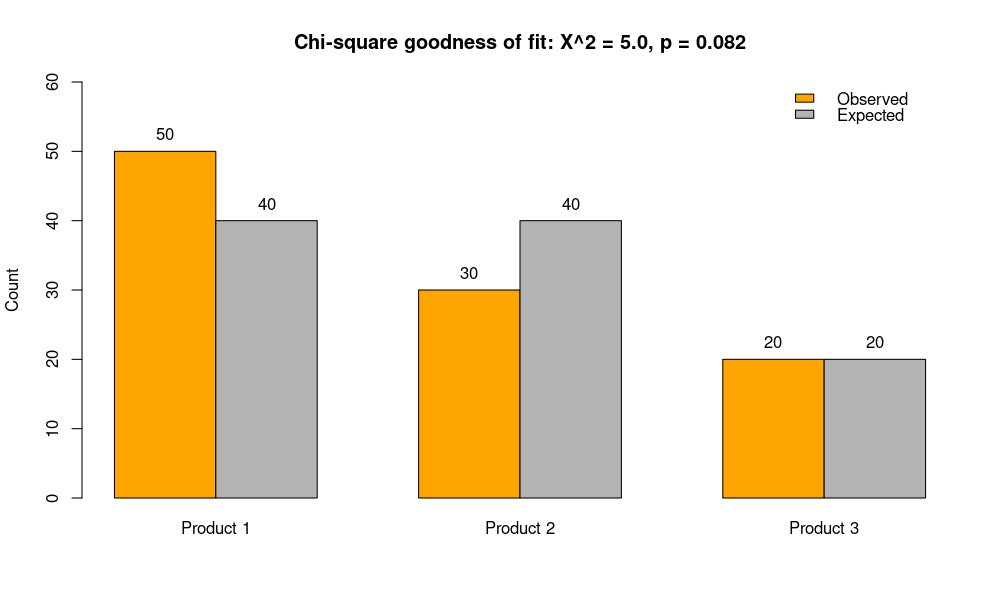

In [5]:
observed <- c(50, 30, 20)
expected_prop <- c(0.4, 0.4, 0.2)
expected <- expected_prop * sum(observed)

chi_result <- chisq.test(x = observed, p = expected_prop)
print(chi_result)
cat("Manual chi-square: sum((O - E)^2 / E) =", sum((observed - expected)^2 / expected), "\n")

# Compare observed vs expected side by side for EACH category
counts <- rbind(Observed = observed, Expected = expected)
colnames(counts) <- c("Product 1", "Product 2", "Product 3")
bp <- barplot(counts, beside = TRUE, col = c("orange", "grey70"), ylim = c(0, 60),
              main = sprintf("Chi-square goodness of fit: X^2 = %.1f, p = %.3f",
                             chi_result$statistic, chi_result$p.value),
              ylab = "Count", legend.text = TRUE, args.legend = list(x = "topright", bty = "n"))
text(bp, counts + 2.5, counts)

## 9. F-Test / One-way ANOVA

            Df Sum Sq Mean Sq F value   Pr(>F)    
group        2  879.7   439.8   33.45 2.45e-10 ***
Residuals   57  749.5    13.1                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


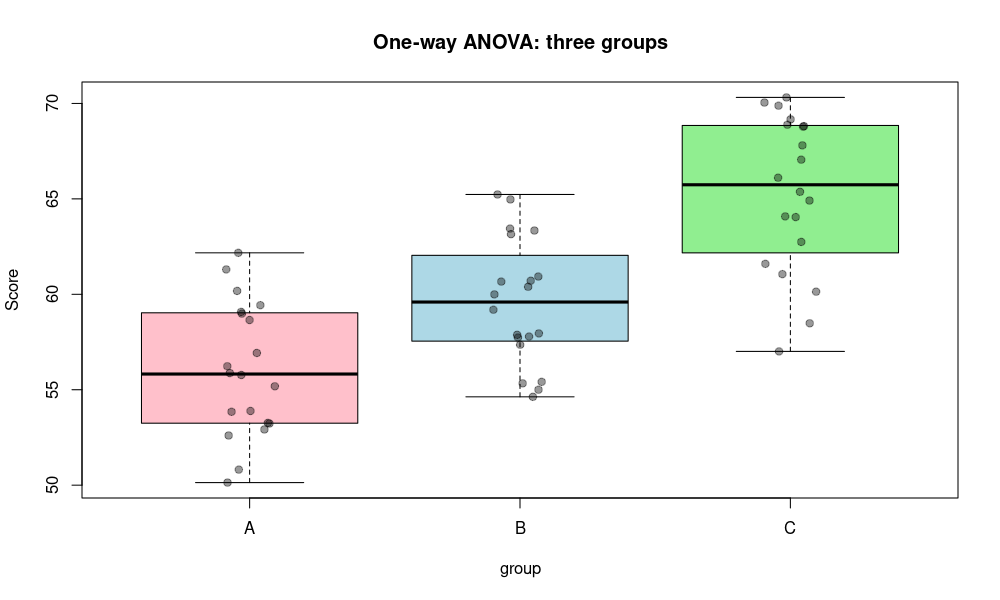

In [6]:
set.seed(23)
data <- data.frame(
  score = c(rnorm(20, 55, 4), rnorm(20, 60, 4), rnorm(20, 65, 4)),
  group = factor(rep(c("A", "B", "C"), each = 20))
)
anova_result <- aov(score ~ group, data = data)
print(summary(anova_result))

boxplot(score ~ group, data = data, main = "One-way ANOVA: three groups",
        col = c("pink", "lightblue", "lightgreen"), ylab = "Score")
stripchart(score ~ group, data = data, vertical = TRUE, method = "jitter", pch = 19,
           col = adjustcolor("black", 0.4), add = TRUE)

## 10. What alpha Really Controls: a Simulation

If $H_0$ is true and we run 10,000 tests at $\alpha = 0.05$, about 5% will **falsely** reject. And when $H_0$ is false, the probability of correctly rejecting (the **power**) grows with the sample size and the effect size.

Share of p < 0.05 when H0 is true: 0.0525 


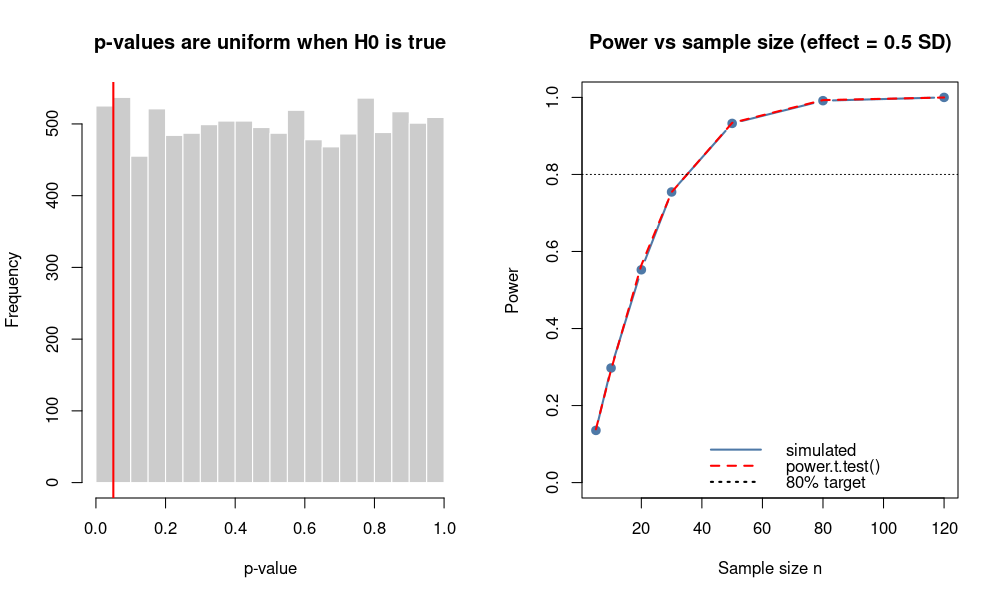

In [7]:
set.seed(99)
# 1) Type I error rate when H0 is TRUE (true mean really is 100)
p_null <- replicate(10000, t.test(rnorm(20, 100, 10), mu = 100)$p.value)
cat("Share of p < 0.05 when H0 is true:", mean(p_null < 0.05), "\n")

# 2) Power when the true mean is 105 (effect = 0.5 SD), for several n
ns <- c(5, 10, 20, 30, 50, 80, 120)
power_sim <- sapply(ns, function(n) mean(replicate(2000, t.test(rnorm(n, 105, 10), mu = 100)$p.value < 0.05)))
power_theory <- sapply(ns, function(n) power.t.test(n = n, delta = 5, sd = 10, type = "one.sample")$power)

par(mfrow = c(1, 2))
hist(p_null, breaks = 20, col = "grey80", border = "white",
     main = "p-values are uniform when H0 is true", xlab = "p-value")
abline(v = 0.05, col = "red", lwd = 2)

plot(ns, power_sim, type = "b", pch = 19, lwd = 2, col = "#4E79A7", ylim = c(0, 1),
     main = "Power vs sample size (effect = 0.5 SD)", xlab = "Sample size n", ylab = "Power")
lines(ns, power_theory, col = "red", lty = 2, lwd = 2)
abline(h = 0.8, lty = 3)
legend("bottomright", c("simulated", "power.t.test()", "80% target"), col = c("#4E79A7", "red", "black"),
       lty = c(1, 2, 3), lwd = 2, bty = "n")

*Insight: Under a true null hypothesis, p-values are uniformly spread between 0 and 1, so "p < 0.05" happens 5% of the time purely by chance. Run 20 tests on noise and you should *expect* one "significant" result — the reason multiple-comparison corrections exist (Lesson 17).*

## Real-World Use Case or Analogy

A hypothesis test works like a **criminal trial**:

- $H_0$: the defendant is innocent (the default).
- The evidence (data) must be strong enough — "beyond reasonable doubt" ($p < \alpha$) — to convict (reject $H_0$).
- **Type I error**: convicting an innocent person. **Type II error**: letting a guilty person go free.
- "Not guilty" is not the same as "proven innocent" — just as "fail to reject $H_0$" is not proof that $H_0$ is true.

Specific tests:
- **Z-Test**: checking whether a machine produces bolts of the target length, when the machine's variance is known.
- **t-Test**: comparing average test scores between two small classrooms.
- **Chi-Square Test**: checking whether observed survey preferences differ from the expected split.
- **ANOVA / F-Test**: comparing average crop yields across several fertilizer types.